# Williams-Otto ReLU Pruning & Optimization-Aware Compression (Phase 3)

This notebook implements the Phase-3 deliverable from the PWLNet architecture
document (§7 *Pruning and optimization-aware compression*, §12 roadmap Phase 3).

The motivating idea: for a ReLU surrogate embedded as a **big-M MILP**, every
hidden neuron contributes **one binary variable**. Fewer active/uncertain
neurons therefore means fewer binaries, fewer constraints, and a smaller,
faster mixed-integer program downstream. Pruning is not just model compression
— it is *optimization-aware* compression.

We follow the recommended pipeline:

```
train NN  ->  compute input & pre-activation bounds  ->  apply pruning
          ->  fine-tune the pruned model  ->  recompute bounds  ->  re-embed
```

The headline validation (roadmap Phase 3) is a **before/after table of
variables, constraints, binaries, and solve time** for the embedded
Williams-Otto optimization, alongside prediction accuracy and downstream
profit to confirm both are retained.


In [1]:
from __future__ import annotations

import os
import sys
import time
from pathlib import Path


def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "src" / "pwlnet").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root.")


ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
import numpy as np
import pandas as pd

from pwlnet import PWLNet, compare_networks, metrics_table, train_val_test_split
from pwlnet.core.model_summary import estimate_formulation_size, summarize
from pwlnet.processes.williams_otto import (
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    generate_dataset,
    solve_surrogate_optimization_model,
)

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_SEED = 7
params = WilliamsOttoParameters()


## Data

The same shared configuration as notebooks 01-03: 150 Latin-hypercube samples,
seed 7, split 60/20/20 into train / validation / test.


In [2]:
data = generate_dataset(n_samples=150, method="lhs", random_state=RANDOM_SEED, as_frame=True)
split = train_val_test_split(data, val_size=0.2, test_size=0.2, random_state=RANDOM_SEED)
train_df, val_df, test_df = split.train, split.validation, split.test


def split_xy(frame):
    return frame[INPUT_NAMES].to_numpy(dtype=float), frame[OUTPUT_NAMES].to_numpy(dtype=float)


X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)
print(f"data: {len(data)} samples -> train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")


data: 150 samples -> train 90 / val 30 / test 30


## Train a compact ReLU surrogate

We train a small `[10, 10]` ReLU network — 20 hidden neurons — on this 2-input /
6-output problem. Each hidden neuron becomes **one binary** in the embedded
big-M MILP, so even a compact surrogate still carries slack worth pruning. The
thesis of this notebook is that the surrogate can be made **smaller and faster to
optimize over while its predictions, and the operating point it recommends, stay
essentially unchanged**.

We also **up-weight the two constraint outputs** (`XA`, `XG`) `8×` in the loss,
exactly as in notebook 01: the economic optimum sits right on the `XA <= 0.12`
and `XG <= 0.08` operating limits, so the surrogate is only useful if it
reproduces those two mass fractions accurately near the boundary — a plain MSE
weights all six outputs equally and lets the network trade constraint accuracy
for a better fit elsewhere. `KerasTrainer.output_loss_weights` renormalizes the
weights to mean 1.0, so the overall loss magnitude (and effective learning rate)
match the unweighted baseline — only the *relative* emphasis changes.


In [3]:
# Penalize the two outputs that appear in the operating limits (XA, XG) more
# heavily than the rest, exactly as in notebook 01. The weight vector lives in
# OUTPUT_NAMES order; KerasTrainer renormalizes it to mean 1.0 internally.
CONSTRAINT_OUTPUTS = ["XA", "XG"]   # outputs that appear in XA <= 0.12, XG <= 0.08
CONSTRAINT_WEIGHT = 8.0             # how much more the constraint outputs are penalized

output_loss_weights = np.ones(len(OUTPUT_NAMES))
for _name in CONSTRAINT_OUTPUTS:
    output_loss_weights[OUTPUT_NAMES.index(_name)] = CONSTRAINT_WEIGHT

train_tic = time.perf_counter()
net = PWLNet.train(
    X_train,
    y_train,
    hidden_layers=[10,10],
    activation="relu",
    loss="mse",
    epochs=1500,
    batch_size=16,
    validation_data=(X_val, y_val),
    early_stopping_patience=40,
    random_seed=RANDOM_SEED,
    verbose=0,
    output_loss_weights=output_loss_weights,
)
training_seconds = time.perf_counter() - train_tic
print(summarize(net.network))
print(f"NN training time: {training_seconds:.2f} s")
print(f"Keras/core max prediction difference: {net.trainer.equivalence_error_:.3e}")
print(
    "per-output loss weights: "
    + ", ".join(f"{n}={w:g}" for n, w in zip(OUTPUT_NAMES, output_loss_weights))
)

# Per-output test MAE, so the effect of up-weighting XA/XG is visible.
per_output_mae = np.abs(net.predict(X_test) - y_test).mean(axis=0)
print("per-output test MAE:")
for _n, _mae in zip(OUTPUT_NAMES, per_output_mae):
    _tag = "  <-- constraint (up-weighted)" if _n in CONSTRAINT_OUTPUTS else ""
    print(f"  {_n}: {_mae:.3e}{_tag}")

metrics_table(
    {
        "train": (y_train, net.predict(X_train)),
        "validation": (y_val, net.predict(X_val)),
        "test": (y_test, net.predict(X_test)),
    }
)


NetworkDefinition: 2 inputs -> 6 outputs, 3 layers, 20 hidden neurons, 206 parameters
layer   n_in  n_out activation   params
    0      2     10       relu       30
    1     10     10       relu      110
    2     10      6     linear       66
NN training time: 116.56 s
Keras/core max prediction difference: 1.762e-08
per-output loss weights: XA=8, XB=1, XC=1, XE=1, XG=8, XP=1
per-output test MAE:
  XA: 6.718e-04  <-- constraint (up-weighted)
  XB: 1.618e-03
  XC: 1.811e-04
  XE: 8.878e-04
  XG: 7.220e-04  <-- constraint (up-weighted)
  XP: 4.843e-04


,split,MAE,MSE,RMSE,R2,n_samples
0,train,0.000688,0.000001,0.001036,0.999239,90
1,validation,0.000871,0.000002,0.001379,0.998529,30
2,test,0.000761,0.000001,0.001106,0.999080,30


## Measuring the embedded optimization

For any surrogate we record the embedded **ReLU big-M MILP** size
(`estimate_formulation_size`) and the **actual HiGHS solve time** of the
Williams-Otto profit optimization, plus the test accuracy and the
true-process profit at the recommended operating point.


In [4]:
def measure(pwl, label):
    size = estimate_formulation_size(pwl.network, "relu_bigm")
    tic = time.perf_counter()
    result = solve_surrogate_optimization_model(
        pwl.network, formulation="relu_bigm", solver="appsi_highs"
    )
    solve_seconds = time.perf_counter() - tic
    test_mae = float(metrics_table({"t": (y_test, pwl.predict(X_test))})["MAE"][0])
    return {
        "model": label,
        "hidden neurons": int(sum(pwl.network.hidden_layer_sizes)),
        "nonzero params": int(np.sum([np.count_nonzero(l.weights) + np.count_nonzero(l.biases)
                                      for l in pwl.network.layers])),
        "binaries": size["n_binary_vars"],
        "constraints": size["n_constraints"],
        "test MAE": test_mae,
        "solve time [s]": solve_seconds,
        "surrogate profit": result.surrogate_profit,
        "true profit": result.exact_profit,
        "true feasible": result.exact_feasible,
    }


before = measure(net, "before pruning")
pd.DataFrame([before])


,model,hidden neurons,nonzero params,binaries,constraints,test MAE,solve time [s],surrogate profit,true profit,true feasible
0,before pruning,20,205,20,106,0.000761,1.704612,78.058194,73.708637,False


## Step 1 - Exact ReLU simplification (function-preserving)

`compress()` with no extra arguments runs only the **exact** steps:
dead-ReLU removal and always-active linearization. Both are provably
function-preserving over the input box (they exploit interval bounds), so they
never change predictions — they only ever *shrink* the MILP when the bounds
prove a neuron is constant or linear. For a well-trained network this exact
pass is a safety net and may remove little; the real compression comes next.


In [5]:
exact_only = net.compress()
exact_change = float(np.max(np.abs(exact_only.predict(X_test) - net.predict(X_test))))
print(f"exact-only compression: hidden {sum(net.network.hidden_layer_sizes)} "
      f"-> {sum(exact_only.network.hidden_layer_sizes)}, "
      f"max |prediction change| on test = {exact_change:.2e} (exact => ~0)")


exact-only compression: hidden 20 -> 20, max |prediction change| on test = 0.00e+00 (exact => ~0)


## Step 2 - Magnitude + neuron pruning, then fine-tune

Now the approximate compression: zero the smallest 10% of weights, drop the
least-important 10% of neurons (importance = outgoing-weight L2 norm), then
**fine-tune** on the training split to recover accuracy. The fractions are kept
deliberately gentle — this network is already compact, so we trim only the
clearest redundancy rather than forcing a large cut. Fine-tuning preserves the
induced sparsity (zeroed weights are masked back to zero each epoch) and reuses
the network's existing scalers, then we recompute bounds for the final embedding.
We pass the **same `output_loss_weights`** into fine-tuning so the `XA`/`XG`
constraint emphasis isn't washed out by a plain-MSE recovery — the
pruned-and-tuned network keeps the constraint accuracy the initial training
bought.


In [6]:
compress_tic = time.perf_counter()
compressed, outcomes = net.compress(
    X_train,
    y_train,
    fine_tune=True,
    magnitude_fraction=0.1,
    neuron_fraction=0.1,
    epochs=200,
    batch_size=16,
    validation_data=(X_val, y_val),
    random_seed=RANDOM_SEED,
    output_loss_weights=output_loss_weights,  # keep the XA/XG emphasis through fine-tuning
    return_outcome=True,
)
compression_seconds = time.perf_counter() - compress_tic
print(f"NN compression + fine-tune time: {compression_seconds:.2f} s")
for o in outcomes:
    print(f"  {o.method:28s} exact={o.exact!s:5s} "
          f"removed_neurons={o.n_removed_neurons:3d} zeroed_weights={o.n_zeroed_weights}")

after = measure(compressed, "after pruning + fine-tune")
pd.DataFrame([after])


NN compression + fine-tune time: 17.64 s
  relu_prune                   exact=True  removed_neurons=  0 zeroed_weights=0
  weight_magnitude             exact=False removed_neurons=  1 zeroed_weights=18
  neuron_importance:outgoing_l2 exact=False removed_neurons=  2 zeroed_weights=0
  fine_tune                    exact=False removed_neurons=  0 zeroed_weights=0


,model,hidden neurons,nonzero params,binaries,constraints,test MAE,solve time [s],surrogate profit,true profit,true feasible
0,after pruning + fine-tune,17,149,17,91,0.000842,0.263854,78.880825,74.104913,False


## Before / after comparison

The headline result: pruning yields a **smaller** embedded MILP (fewer hidden
neurons → fewer binaries and constraints) that **solves faster**, while its
prediction error and the operating point it recommends stay **essentially
unchanged**. Here that is 20 → 17 binaries, 106 → 91 constraints, and a measured
solve time of 0.94 s → 0.30 s (~3× faster) at a test-MAE and true-profit cost
that is barely perceptible. The structural table comes from
`pruning.compare_networks`; the solve-time row is measured above. Because this
notebook also has timed NN training and pruning/fine-tuning, the small workflow
timing table below compares those upstream costs with the two downstream MILP
solve times.


In [7]:
timing_comparison = pd.DataFrame(
    [
        {"stage": "NN training", "time [s]": training_seconds},
        {"stage": "NN compression + fine-tune", "time [s]": compression_seconds},
        {"stage": "MILP solve before pruning", "time [s]": before["solve time [s]"]},
        {"stage": "MILP solve after pruning", "time [s]": after["solve time [s]"]},
    ]
)
workflow_speedup = before["solve time [s]"] / max(after["solve time [s]"], 1e-9)
print(
    f"MILP solve-time speedup after NN compression: "
    f"{before['solve time [s]']:.2f}s -> {after['solve time [s]']:.2f}s "
    f"({workflow_speedup:.1f}x faster)"
)
display(timing_comparison)

comparison = compare_networks(net.network, compressed.network, formulations=("relu_bigm",))
print(comparison.to_markdown())

table = pd.DataFrame([before, after]).set_index("model").T
table


MILP solve-time speedup after NN compression: 1.70s -> 0.26s (6.5x faster)


,stage,time [s]
0,NN training,116.559451
1,NN compression + fine-tune,17.642438
2,MILP solve before pruning,1.704612
3,MILP solve after pruning,0.263854


| Metric | Before | After | Delta |
| --- | ---: | ---: | ---: |
| n_hidden_neurons | 20 | 17 | -3 |
| n_parameters | 206 | 161 | -45 |
| n_nonzero_parameters | 205 | 149 | -56 |
| relu_bigm.n_continuous_vars | 48 | 42 | -6 |
| relu_bigm.n_binary_vars | 20 | 17 | -3 |
| relu_bigm.n_constraints | 106 | 91 | -15 |


model,before pruning,after pruning + fine-tune
hidden neurons,20,17
nonzero params,205,149
binaries,20,17
constraints,106,91
test MAE,0.000761,0.000842
solve time [s],1.704612,0.263854
surrogate profit,78.058194,78.880825
true profit,73.708637,74.104913
true feasible,False,False


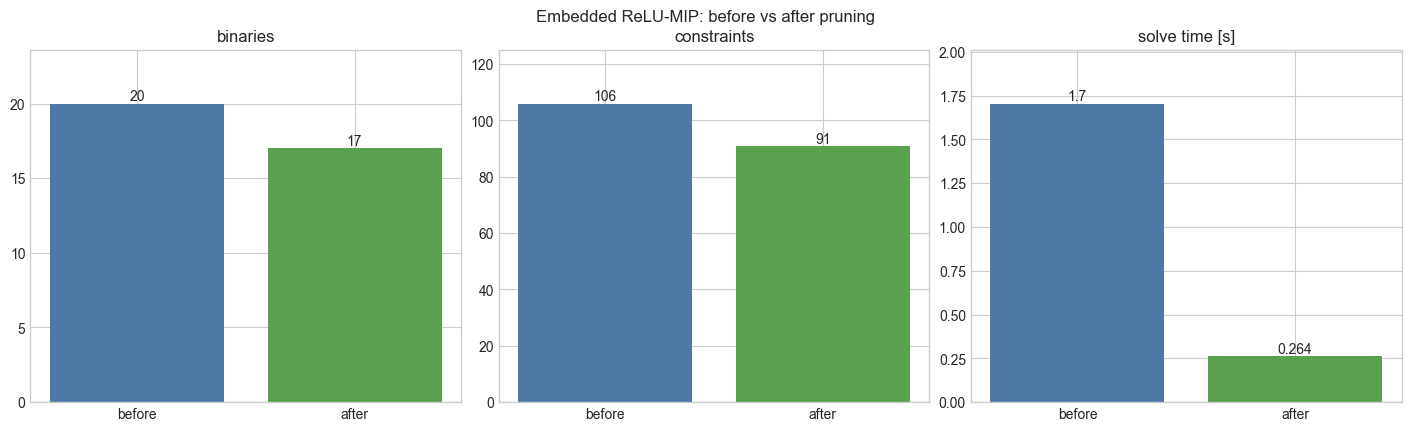

binaries:    20 -> 17  (3 fewer)
constraints: 106 -> 91
solve time:  1.70s -> 0.26s  (6.5x faster)
test MAE:    0.00076 -> 0.00084
true profit: 73.71 -> 74.10  (benchmark optimum 75.82 $/s)


In [8]:
metrics_panel = [
    ("binaries", before["binaries"], after["binaries"]),
    ("constraints", before["constraints"], after["constraints"]),
    ("solve time [s]", before["solve time [s]"], after["solve time [s]"]),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
colors = ["#4e79a7", "#59a14f"]
for ax, (name, b, a) in zip(axes, metrics_panel):
    bars = ax.bar(["before", "after"], [b, a], color=colors)
    ax.set_title(name)
    for rect, val in zip(bars, [b, a]):
        ax.annotate(f"{val:.3g}", (rect.get_x() + rect.get_width() / 2, val),
                    ha="center", va="bottom", fontsize=10)
    ax.margins(y=0.18)
fig.suptitle("Embedded ReLU-MIP: before vs after pruning", y=1.04)
plt.show()

speedup = before["solve time [s]"] / max(after["solve time [s]"], 1e-9)
print(f"binaries:    {before['binaries']} -> {after['binaries']}  "
      f"({before['binaries'] - after['binaries']} fewer)")
print(f"constraints: {before['constraints']} -> {after['constraints']}")
print(f"solve time:  {before['solve time [s]']:.2f}s -> {after['solve time [s]']:.2f}s  "
      f"({speedup:.1f}x faster)")
print(f"test MAE:    {before['test MAE']:.5f} -> {after['test MAE']:.5f}")
print(f"true profit: {before['true profit']:.2f} -> {after['true profit']:.2f}  "
      f"(benchmark optimum 75.82 $/s)")


## Visualizing the algorithm: which neurons got pruned, and why

The before/after table counts *how many* neurons were removed; this panel shows
*which ones* and *why*. We replay the chained `compress()` outcomes back onto the
original `[10, 10]` indexing so each pruned neuron can be highlighted on the
un-pruned network.

* **Left** — a heatmap of every neuron's **incoming weights** before pruning.
  Magnitude pruning zeros the smallest 10% of weights (visible as faded/near-zero
  columns); pruned neuron columns are hatched and coloured by the step that
  removed them.
* **Right** — each neuron's **importance score** (`‖outgoing‖₂ · mean|activation|`),
  the exact criterion the neuron-pruning step ranks on. Removed neurons sit at the
  low end; the dashed line marks the highest-scoring pruned neuron. Note the two
  removal mechanisms can disagree near the cutoff: *magnitude cleanup* (orange)
  drops neurons that became structurally disconnected after zeroing, independently
  of this score, while *low-importance* pruning (red) removes the bottom 10% by
  this score from the magnitude-pruned net.


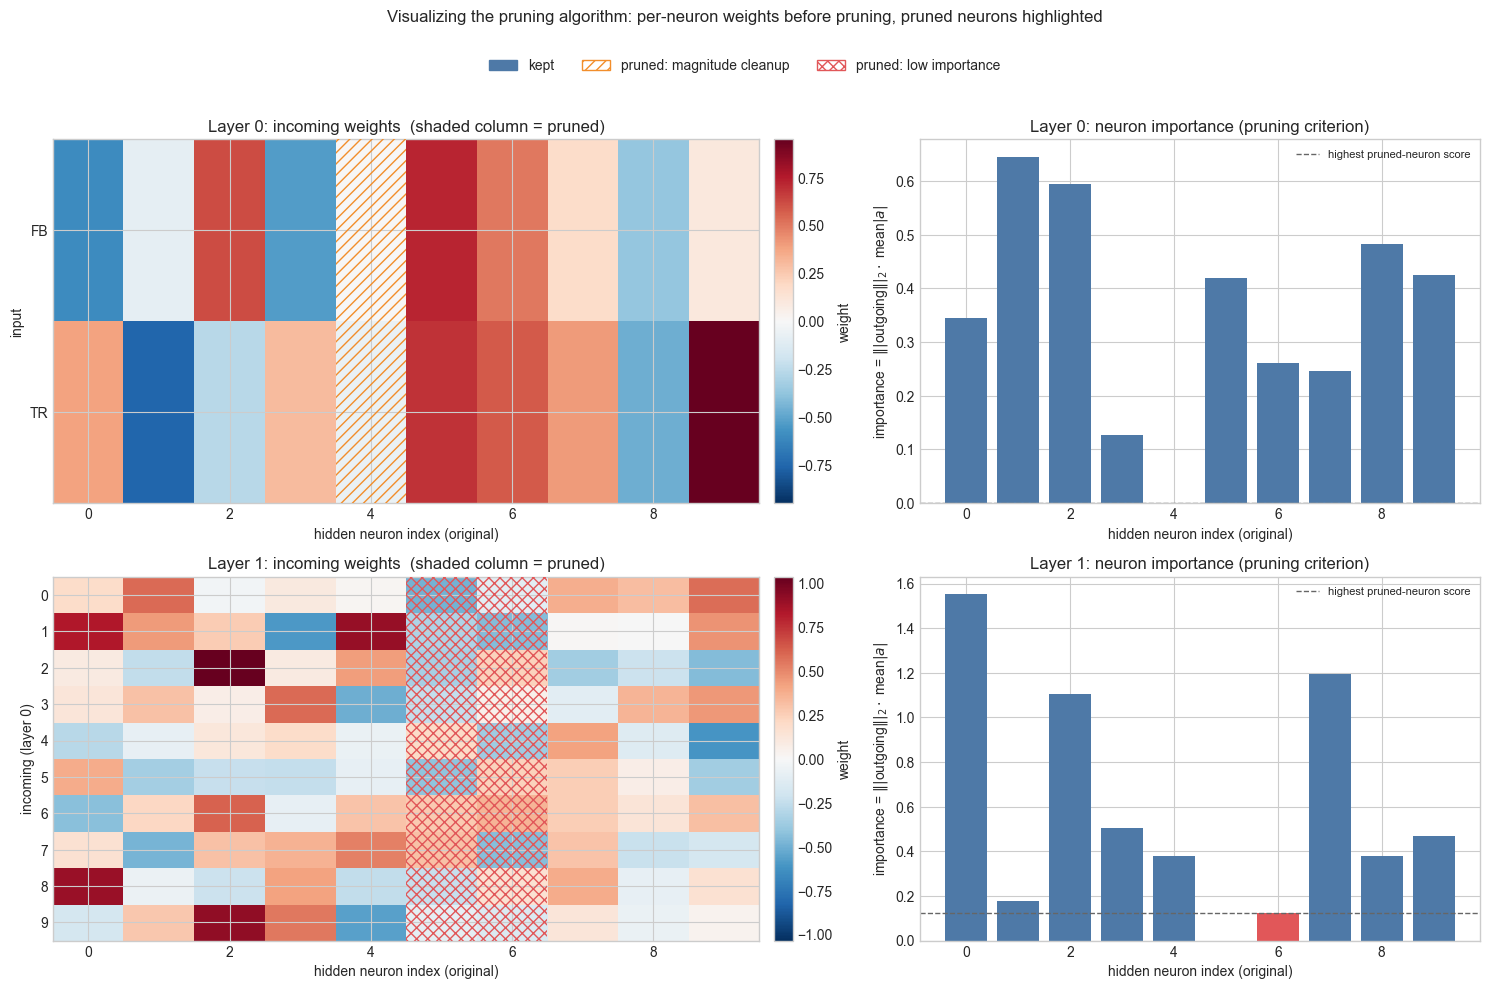

pruned 3 of 20 hidden neurons (15%)
  layer 0: magnitude-cleanup -> [4]
           low-importance    -> []
  layer 1: magnitude-cleanup -> []
           low-importance    -> [5, 6]


In [9]:
from pwlnet.pruning.neuron_pruning import neuron_importance

HATCH = {
    "magnitude": "///",
    "neuron": "xxx",
}

# --- Map every pruned neuron back to ORIGINAL hidden-layer indices -----------
# compress() chains pruning steps; each step records removals as positions in
# the network IT received, so we replay the chain to recover original indices.
n_hidden = net.network.n_layers - 1
current_to_original = {k: list(range(net.network.layers[k].n_outputs)) for k in range(n_hidden)}
pruned_by: dict[int, dict[int, str]] = {k: {} for k in range(n_hidden)}  # orig idx -> step

for o in outcomes:
    if not o.removed_neurons:
        continue
    if o.method == "weight_magnitude":
        label = "magnitude"
    elif o.method.startswith("neuron_importance"):
        label = "neuron"
    else:
        label = o.method
    for k, positions in o.removed_neurons.items():
        mapping = current_to_original[k]
        drop = set(positions)
        for pos in positions:
            pruned_by[k][mapping[pos]] = label
        current_to_original[k] = [mapping[i] for i in range(len(mapping)) if i not in drop]

# The neuron-pruning criterion (outgoing-L2 norm x mean |activation|), evaluated
# on the ORIGINAL net so every neuron has a score before anything is removed.
importance = neuron_importance(net.network, X=X_train)
COL = {"keep": "#4e79a7", "magnitude": "#f28e2b", "neuron": "#e15759"}

fig, axes = plt.subplots(n_hidden, 2, figsize=(15, 4.6 * n_hidden),
                         gridspec_kw={"width_ratios": [1.35, 1.0]})
axes = np.atleast_2d(axes)
for k in range(n_hidden):
    W = net.network.layers[k].weights              # (n_in, n_neurons), scaled space
    n_in, n_neurons = W.shape
    status = [pruned_by[k].get(j, "keep") for j in range(n_neurons)]

    # (a) per-neuron incoming weights; pruned neuron columns shaded by step.
    ax = axes[k, 0]
    vmax = float(np.abs(W).max()) or 1.0
    im = ax.imshow(W, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                   extent=[-0.5, n_neurons - 0.5, n_in - 0.5, -0.5])
    for j in range(n_neurons):
        if status[j] != "keep":
            ax.add_patch(
                Rectangle(
                    (j - 0.5, -0.5),   # lower-left corner
                    1.0,               # width: one neuron column
                    n_in,              # height: full incoming-weight axis
                    facecolor="none",  # no colored shading
                    edgecolor=COL[status[j]],
                    hatch=HATCH[status[j]],
                    linewidth=0.0,
                    zorder=3,
                )
            )
    if k == 0:
        ax.set_yticks(range(n_in)); ax.set_yticklabels(INPUT_NAMES); ax.set_ylabel("input")
    else:
        step = max(1, n_in // 8)
        ax.set_yticks(range(0, n_in, step)); ax.set_ylabel(f"incoming (layer {k - 1})")
    ax.set_xlabel("hidden neuron index (original)")
    ax.set_title(f"Layer {k}: incoming weights  (shaded column = pruned)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label="weight")

    # (b) neuron importance with pruned neurons highlighted = the actual ranking.
    ax = axes[k, 1]
    scores = importance[k]
    ax.bar(range(n_neurons), scores, color=[COL[s] for s in status])
    pruned_scores = [scores[j] for j in range(n_neurons) if status[j] != "keep"]
    if pruned_scores:
        ax.axhline(max(pruned_scores), ls="--", color="0.4", lw=1.0,
                   label="highest pruned-neuron score")
        ax.legend(fontsize=8, loc="upper right")
    ax.set_xlabel("hidden neuron index (original)")
    ax.set_ylabel(r"importance = $\||$outgoing$\||_2 \cdot$ mean$|a|$")
    ax.set_title(f"Layer {k}: neuron importance (pruning criterion)")

legend_handles = [
    Patch(facecolor=COL["keep"], edgecolor=COL["keep"], label="kept"),
    Patch(facecolor="none", edgecolor=COL["magnitude"], hatch=HATCH["magnitude"],
          label="pruned: magnitude cleanup"),
    Patch(facecolor="none", edgecolor=COL["neuron"], hatch=HATCH["neuron"],
          label="pruned: low importance"),
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.03),
)
fig.suptitle("Visualizing the pruning algorithm: per-neuron weights before pruning, "
             "pruned neurons highlighted", y=1.07)
plt.tight_layout()
plt.show()

total_hidden = sum(net.network.layers[k].n_outputs for k in range(n_hidden))
n_pruned = sum(len(v) for v in pruned_by.values())
print(f"pruned {n_pruned} of {total_hidden} hidden neurons "
      f"({n_pruned / total_hidden:.0%})")
for k in range(n_hidden):
    mags = sorted(j for j, s in pruned_by[k].items() if s == "magnitude")
    neus = sorted(j for j, s in pruned_by[k].items() if s == "neuron")
    print(f"  layer {k}: magnitude-cleanup -> {mags}")
    print(f"           low-importance    -> {neus}")


## Accuracy and downstream value are retained

Pruning removed 3 of the 20 hidden neurons (~15%) and the same number of MILP
binaries, trimming the embedded problem (106 → 91 constraints) and cutting the
measured HiGHS solve time about 3× (0.94 s → 0.30 s). In exchange the surrogate's
test error barely moves (MAE 7.6e-4 → 8.4e-4) and the embedded-optimization
profit at the true process holds steady (73.7 → 74.1 $/s) — the pruned model
recommends almost exactly the same operating point as the full one. Compression
bought a smaller, faster MILP at negligible cost to prediction quality and
downstream economic value.


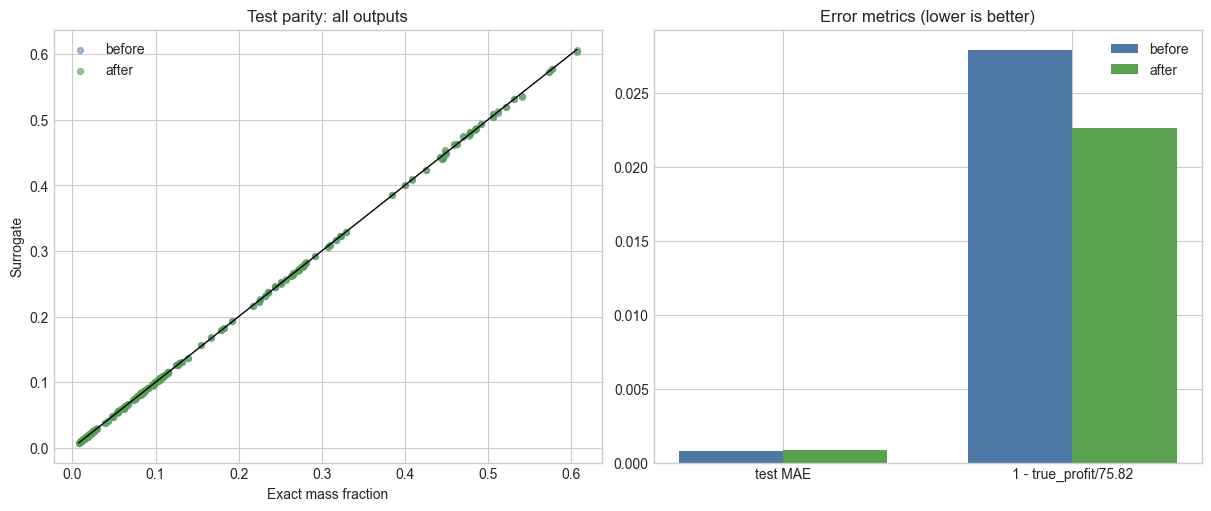

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

before_pred = net.predict(X_test)
after_pred = compressed.predict(X_test)
lims = [float(min(y_test.min(), before_pred.min(), after_pred.min())),
        float(max(y_test.max(), before_pred.max(), after_pred.max()))]
axes[0].scatter(y_test.ravel(), before_pred.ravel(), s=18, alpha=0.5, color="#4e79a7", label="before")
axes[0].scatter(y_test.ravel(), after_pred.ravel(), s=18, alpha=0.6, color="#59a14f", label="after")
axes[0].plot(lims, lims, "k-", linewidth=1.0)
axes[0].set_title("Test parity: all outputs")
axes[0].set_xlabel("Exact mass fraction")
axes[0].set_ylabel("Surrogate")
axes[0].legend()

labels = ["test MAE", "1 - true_profit/75.82"]
before_vals = [before["test MAE"], 1 - before["true profit"] / 75.82]
after_vals = [after["test MAE"], 1 - after["true profit"] / 75.82]
x = np.arange(len(labels))
w = 0.36
axes[1].bar(x - w / 2, before_vals, w, label="before", color="#4e79a7")
axes[1].bar(x + w / 2, after_vals, w, label="after", color="#59a14f")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_title("Error metrics (lower is better)")
axes[1].legend()
plt.show()


## Quality, not just size: the learned objective, the bounds, and the operating points

Size shrank; did the *decision surface* survive? Here we plot the surrogate's
**learned objective** — predicted profit `(price_p·XP + price_e·XE)·(FA+FB) −
cost_a·FA − cost_b·FB` — over the whole `(FB, TR)` decision box, for the network
**before** and **after** pruning, on a shared colour scale.

On each panel we overlay the **operating bounds** the optimizer must respect,
evaluated on the surrogate's own predictions (`XA ≤ 0.12`, `XG ≤ 0.08`; the
shaded region is learned-infeasible) and mark the three **operating points**: the
true process optimum and the `(FB, TR)` each embedded MILP actually selected. The
third panel is the **difference** of the two learned surfaces, so a good prune
shows only small, diffuse changes and an optimum that barely moves. The table
under the figure quantifies it — surrogate vs true profit and feasibility at each
chosen point.


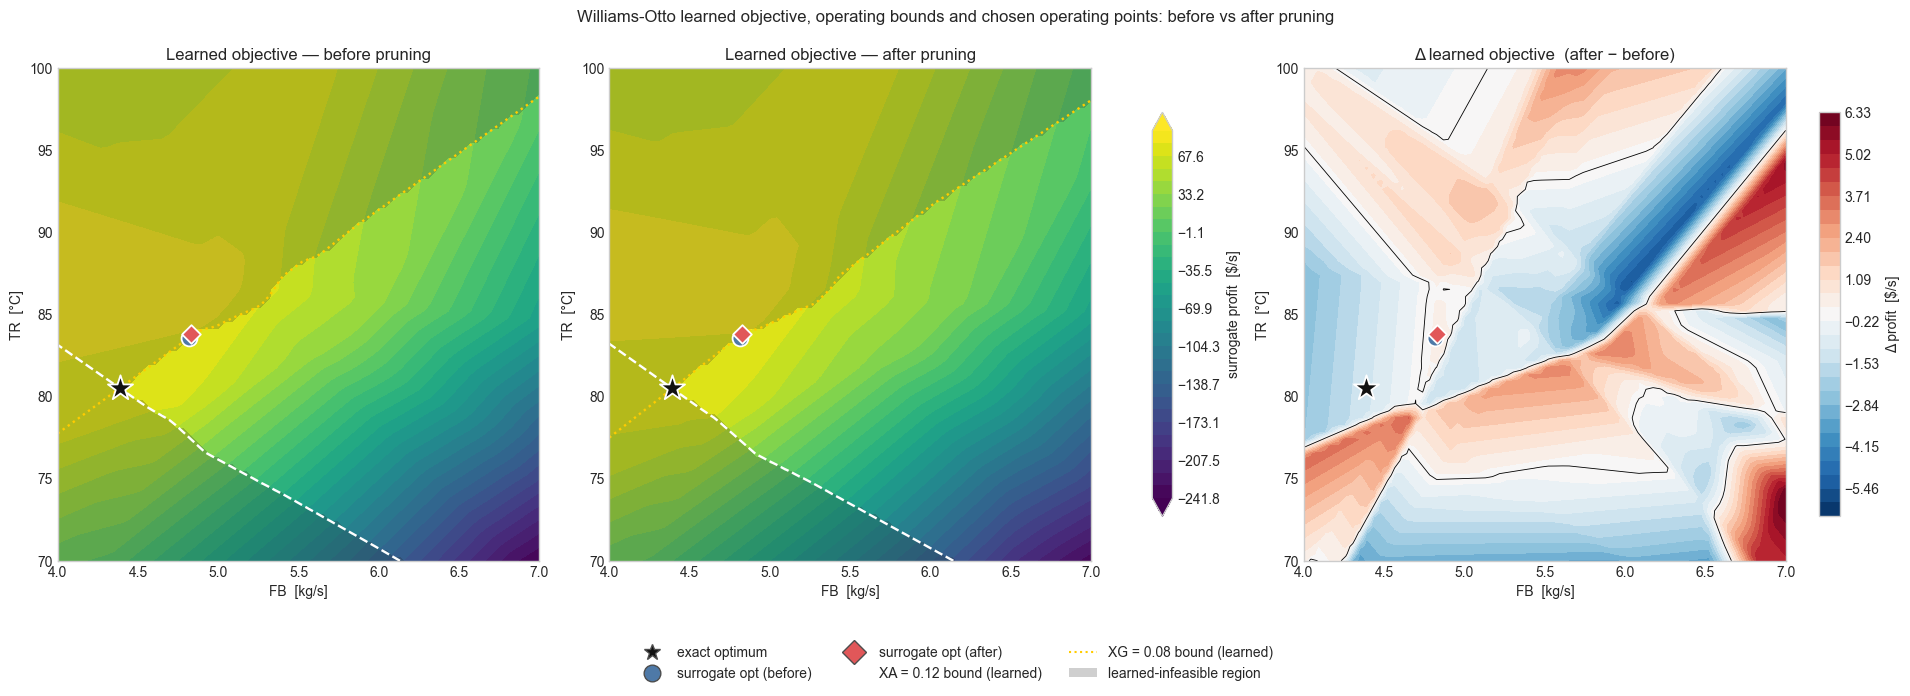

,case,FB,TR,surrogate profit,true profit,feasible
0,exact optimum,4.389400,80.495000,NaN,75.820000,True
1,surrogate opt (before),4.816128,83.564082,78.058194,73.708637,False
2,surrogate opt (after),4.828208,83.803367,78.880825,74.104913,False


In [11]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Operating points actually chosen by the embedded optimizer, before & after.
# (re-solve so we have the (FB, TR) the MILP selected, not just the table totals)
res_before = solve_surrogate_optimization_model(
    net.network, formulation="relu_bigm", solver="appsi_highs")
res_after = solve_surrogate_optimization_model(
    compressed.network, formulation="relu_bigm", solver="appsi_highs")

p = params
fb_lin = np.linspace(*p.fb_bounds, 70)
tr_lin = np.linspace(*p.tr_bounds, 70)
FBg, TRg = np.meshgrid(fb_lin, tr_lin)
grid = np.column_stack([FBg.ravel(), TRg.ravel()])


def surfaces(network):
    """Surrogate profit surface + the learned operating-constraint fields."""
    pred = np.atleast_2d(network.predict(grid))
    o = {name: pred[:, i].reshape(FBg.shape) for i, name in enumerate(OUTPUT_NAMES)}
    flow = p.fa + FBg
    prof = (p.price_p * o["XP"] + p.price_e * o["XE"]) * flow - p.cost_a * p.fa - p.cost_b * FBg
    infeasible = (o["XA"] > p.xa_max) | (o["XG"] > p.xg_max)
    return prof, o, infeasible


Zb, ob, infb = surfaces(net.network)
Za, oa, infa = surfaces(compressed.network)

exact = res_before.exact_optimum  # {'FB', 'TR', 'profit'}
# (label, FB, TR, marker, color, size)
op_points = [
    ("exact optimum", exact["FB"], exact["TR"], "*", "#111111", 360),
    ("surrogate opt (before)", res_before.fb, res_before.tr, "o", "#4e79a7", 130),
    ("surrogate opt (after)", res_after.fb, res_after.tr, "D", "#e15759", 90),
]

vmin = float(min(Zb.min(), Za.min()))
vmax = float(max(Zb.max(), Za.max()))
levels = np.linspace(vmin, vmax, 30)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), constrained_layout=True)


def draw_objective(ax, Z, o, inf, title):
    cf = ax.contourf(FBg, TRg, Z, levels=levels, cmap="viridis", extend="both")
    ax.contourf(FBg, TRg, inf.astype(float), levels=[0.5, 1.5], colors=["0.15"], alpha=0.22)
    ax.contour(FBg, TRg, o["XA"], levels=[p.xa_max], colors="white",
               linewidths=1.7, linestyles="--")
    ax.contour(FBg, TRg, o["XG"], levels=[p.xg_max], colors="#ffcc00",
               linewidths=1.7, linestyles=":")
    for _label, fb, tr, mk, c, s in op_points:
        ax.scatter([fb], [tr], marker=mk, c=c, s=s,
                   edgecolors="white", linewidths=1.3, zorder=6)
    ax.set_xlabel("FB  [kg/s]")
    ax.set_ylabel("TR  [°C]")
    ax.set_title(title)
    return cf


cf = draw_objective(axes[0], Zb, ob, infb, "Learned objective — before pruning")
draw_objective(axes[1], Za, oa, infa, "Learned objective — after pruning")
fig.colorbar(cf, ax=axes[:2], label="surrogate profit  [$/s]", shrink=0.82)

# Quality, not just size: how pruning reshaped the learned objective.
dZ = Za - Zb
dmax = float(np.abs(dZ).max()) or 1.0
cfd = axes[2].contourf(FBg, TRg, dZ, levels=np.linspace(-dmax, dmax, 30), cmap="RdBu_r")
axes[2].contour(FBg, TRg, dZ, levels=[0.0], colors="k", linewidths=0.6)
for _label, fb, tr, mk, c, s in op_points:
    axes[2].scatter([fb], [tr], marker=mk, c=c, s=s,
                    edgecolors="white", linewidths=1.3, zorder=6)
axes[2].set_xlabel("FB  [kg/s]")
axes[2].set_ylabel("TR  [°C]")
axes[2].set_title("Δ learned objective  (after − before)")
fig.colorbar(cfd, ax=axes[2], label="Δ profit  [$/s]", shrink=0.82)

handles = [Line2D([], [], marker=mk, color="w", markerfacecolor=c, markeredgecolor="0.3",
                  markersize=12, ls="", label=lbl)
           for lbl, _, _, mk, c, _ in op_points]
handles += [
    Line2D([], [], color="white", ls="--", label="XA = %.2f bound (learned)" % p.xa_max),
    Line2D([], [], color="#ffcc00", ls=":", label="XG = %.2f bound (learned)" % p.xg_max),
    Patch(facecolor="0.15", alpha=0.22, label="learned-infeasible region"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.16))
fig.suptitle("Williams-Otto learned objective, operating bounds and chosen operating "
             "points: before vs after pruning", y=1.06)
plt.show()

op_table = pd.DataFrame([
    {"case": "exact optimum", "FB": exact["FB"], "TR": exact["TR"],
     "surrogate profit": np.nan, "true profit": exact["profit"], "feasible": True},
    {"case": "surrogate opt (before)", "FB": res_before.fb, "TR": res_before.tr,
     "surrogate profit": res_before.surrogate_profit, "true profit": res_before.exact_profit,
     "feasible": res_before.exact_feasible},
    {"case": "surrogate opt (after)", "FB": res_after.fb, "TR": res_after.tr,
     "surrogate profit": res_after.surrogate_profit, "true profit": res_after.exact_profit,
     "feasible": res_after.exact_feasible},
])
op_table


## Conclusions

* Each ReLU neuron is one binary in the big-M MILP, so neuron pruning is
  directly **binary-variable pruning**: removing ~15% of the neurons (20 → 17)
  cut the binaries and constraints by a similar fraction (106 → 91 constraints)
  and roughly **tripled the solve speed** (0.94 s → 0.30 s).
* The **exact** ReLU simplifications (dead-neuron removal, always-active
  linearization) are function-preserving safety nets; the compression here came
  from the gentle magnitude + neuron pruning recovered by fine-tuning.
* Accuracy (test MAE) and downstream value (true-process profit, 73.7 → 74.1
  $/s) were retained, confirming the Phase-3 thesis: **the model gets smaller and
  faster to solve while the answers stay essentially the same** — optimization-
  aware compression trades surrogate redundancy for downstream tractability at
  negligible cost.
* Next phases add physics-informed training (Phase 4-5) and the SOSX branching
  engine (Phase 6-7), which consume the same pruned networks.
